# Five-modality mouse brain: Fig. 3e-j

The saved RNA, protein, ATAC, H3K27ac and H3K27me3 inputs lead to a 128-dimensional MELON embedding and the final 17-domain partition.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/05_Mouse_brain_five_modalities/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "05_Mouse_brain_five_modalities"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Read the saved MELON stages

The modality inputs, native MELON embedding, clustering representation and UMAP coordinates are stored separately.

In [2]:
inputs = np.load(DATA / "02_model_inputs/MELON/features.npz", allow_pickle=False)
embeddings = np.load(DATA / "03_embeddings/aligned_embeddings.npz", allow_pickle=False)
labels = read_indexed(DATA / "04_clusters/final_clusters.csv")
assert len(labels) == 9567
assert np.array_equal(embeddings["barcodes"].astype(str), labels.index.to_numpy())
display(pd.DataFrame({"stage": ["MELON modality inputs", "MELON native", "MELON clustering"],
    "shape": [str([inputs[m].shape for m in ["RNA", "Protein", "ATAC", "H3K27ac", "H3K27me3"]]),
              str(embeddings["MELON_native128"].shape), str(embeddings["MELON_clustering_PCA20_L2"].shape)]}))

,stage,shape
0,MELON modality inputs,"[(9567, 30), (9567, 30), (9567, 30), (9567, 30..."
1,MELON native,"(9567, 128)"
2,MELON clustering,"(9567, 20)"


## 2. Display the MELON spatial domains

`MELON_14_15` identifies the stored MELON result with spatial export k = 14 and a 15-neighbor clustering graph.

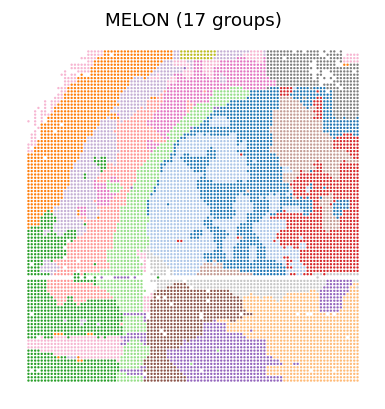

In [3]:
methods = ["MELON_14_15"]
palette = saved_palette(DATA / "04_clusters/cluster_palette.csv")
show(spatial_panels(labels, methods, colors=palette, ncols=1, point_size=2))

## 3. Display the saved MELON UMAP

Read the existing MELON coordinates and domain colors.

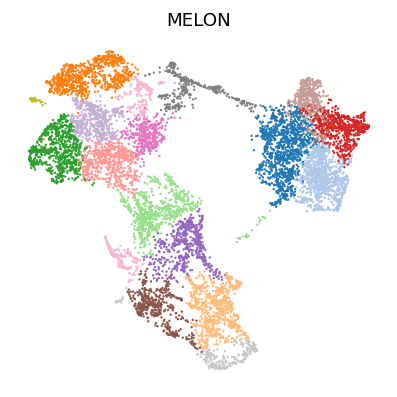

In [4]:
umap = pd.read_csv(DATA / "04_clusters/UMAP_coordinates.csv", dtype={"barcode": str, "cluster": str})
show(saved_umap_panels(umap, palette, methods))

The MELON source files and any additional downstream inputs are listed in [figure sources](../FIGURE_SOURCES.md).